# 02 - EDA: findings F1-F10, observations O1-O3 

In [1]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from energymind import eda, eda_features, eda_plots as P, io
from energymind.config import load_settings

warnings.filterwarnings("ignore", category=FutureWarning)
%config InlineBackend.figure_format = "png"
plt.rcParams["figure.dpi"] = 110          # notebook display only; files are saved at 300 dpi

settings = load_settings()
df, fx, raw, labels, splits = eda.prepare(settings)   # clean baseline, +EDA features, raw subset, provided labels
findings = eda.compute_findings(df, raw)
observations = eda.compute_observations(fx, splits)
FIG = io.resolve("results/figures")
by_code = {f.code: f for f in [*findings, *observations]}

def metrics(code):
    f = by_code[code]
    print(f"{f.code} - {f.title}")
    for label, value in f.metrics:
        print(f"   {label}: {value}")

print(f"baseline: {df.shape[0]:,} rows x {df.shape[1]} columns | 13 households | figures -> {FIG}")

baseline: 227,760 rows x 54 columns | 13 households | figures -> /home/claude/tsyp/EnergyMind/results/figures


## Findings at a glance (computed)

In [2]:
pd.DataFrame(
    [(f.code, f.title, f.consequence) for f in [*findings, *observations]],
    columns=["#", "Finding", "Consequence"],
).style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"})

#,Finding,Consequence
F1,Electrical identities hold almost exactly,"The data is generated by formula, so a physics check is an exact detector; injection and imputation must propagate consistently across channels."
F2,Provided labels are trivial single-interval events,They are trivially detectable and unrealistic; use them as a sanity test set and build the real benchmark by injection.
F3,Rolling features include the current value (leakage),Using them is label leakage and they would not move on injection; drop all 64 and recompute past-only features after injection.
F4,"Electrical parameters are 230 V / 50 Hz, cost in EUR","Not US parameters (Austin is 120/240 V, 60 Hz); frame honestly as Tunisian-grid-compatible parameters on an Austin calendar and climate."
F5,"Weather is generated per row, not shared",Weather features are weak evidence; do not build 'genuine heat-wave' logic on them without injecting coherent events.
F6,Thermal load is V-shaped in temperature (linear correlation is blind to it),"Heating and cooling sub-meters both rise with the distance from ~20 C (so both are high in winter and summer and their labels are not physical); the zero linear correlation hides a strong non-monotonic dependence. Load is higher at night because the occupancy schedule, not temperature, sets the daily profile. Temperature is a valid explanatory feature through |T - 20 C|, but it is generated per household (F5), so coherent heat-wave events must still be injected."
F7,Sub-meters are not a closed energy balance,"There is an unmetered remainder; a 'sub-meters > total' check is useful but noisy, and it fires only where PV makes the net total smaller than the gross sub-meters."
F8,Metadata contradicts itself,Do not use size or type as features or as explanations.
F9,Natural flat runs reach ~16 intervals,"Stuck-at injections shorter than ~8 h are indistinguishable by flatness alone; use multi-channel evidence. The natural runs sit at near-zero load, which the sub-meter flag already excludes from the quality mask."
F10,Households correlate daily but weakly at 30 min,Cross-household coherence is usable to separate genuine events from faults at hourly/daily scale.


## A. Dataset overview and data quality

**Fig. 1** is the one-page summary of the panel: record status, temporal coverage, load distribution,
seasonal energy, daily profile and the load-temperature relation (panel f already shows the U-shape that
section D explains). **Fig. 2** shows where the provided anomalies and the 8 missing records sit; isolated
single slots are imputed with the electrical identities rebuilt, the 2 two-slot runs stay NaN.

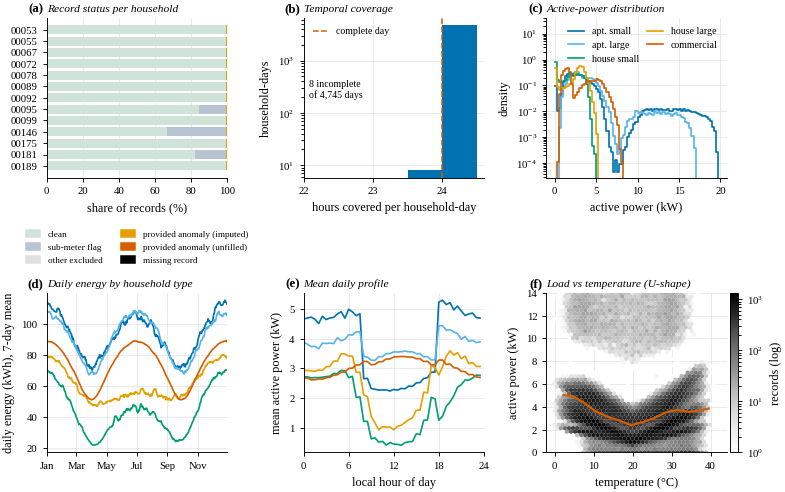

In [3]:
fig = P.fig_dataset_overview(fx, FIG); plt.show()

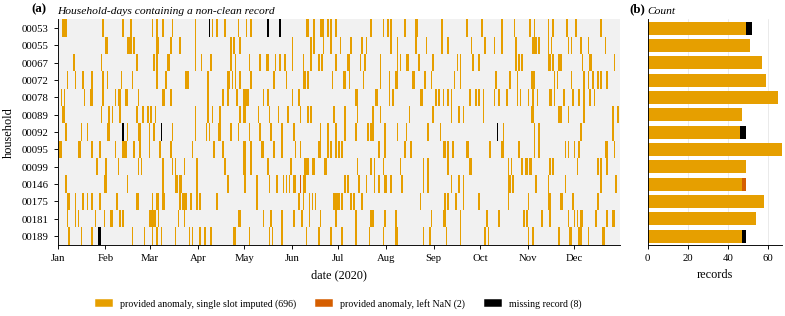

In [4]:
fig = P.fig_missing_record_map(fx, FIG); plt.show()

## B. Physics consistency and the provided labels (F1, F2, F4)

The generator satisfies the electrical identities almost exactly (F1), so a physics check is an *exact*
detector, and the provided `spike`/`dropout` labels break it by orders of magnitude (F2) - which is why they
are only a sanity-test set. Voltage and frequency sit inside the plausibility bounds (F4, 230 V / 50 Hz).

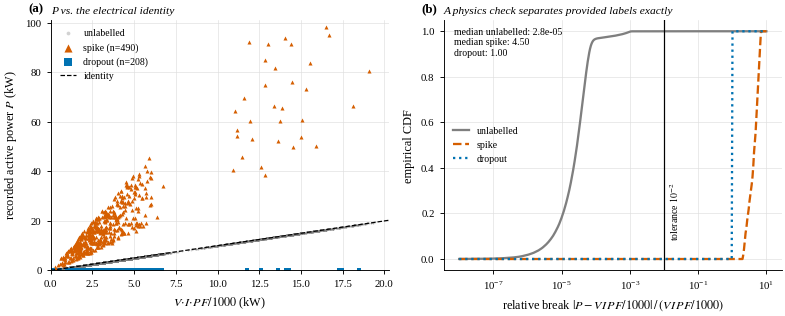

F1 - Electrical identities hold almost exactly
   max |r_S|, |r_VI|, |r_E|, |r_PF|: 2.48e-04
   median |r_S|: 8.29e-06
   median rel. cost = E*tariff error: 5.54e-06
F2 - Provided labels are trivial single-interval events
   runs: 697
   runs of length 1: 696
   max run length: 2
   dropout rows with P = 0: 1.000
   spike median |P - V*I*PF/1000| / P: 0.818


In [5]:
fig = P.fig_power_identity(raw, FIG); plt.show()
metrics("F1"); metrics("F2")

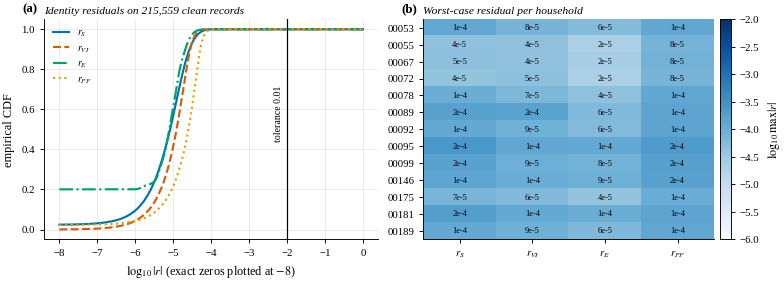

In [6]:
fig = P.fig_physics_residuals(fx, settings.data.physics_residual_tolerance, FIG); plt.show()

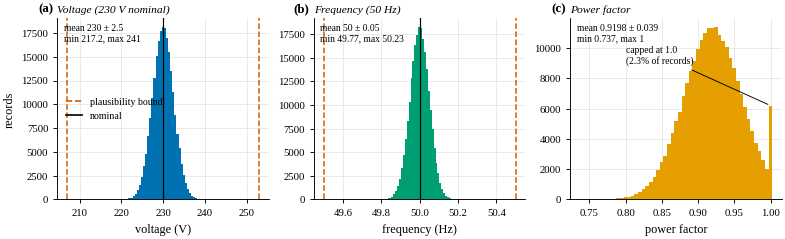

F4 - Electrical parameters are 230 V / 50 Hz, cost in EUR
   voltage min / median / max: 217 / 230 / 241 V
   frequency mean +/- std: 50.00 +/- 0.05 Hz
   tariff_rate median: 0.250


In [7]:
b = settings.data.bounds
fig = P.fig_electrical_parameters(fx, {"voltage_v": b.voltage_v, "frequency_hz": b.frequency_hz}, FIG); plt.show()
metrics("F4")

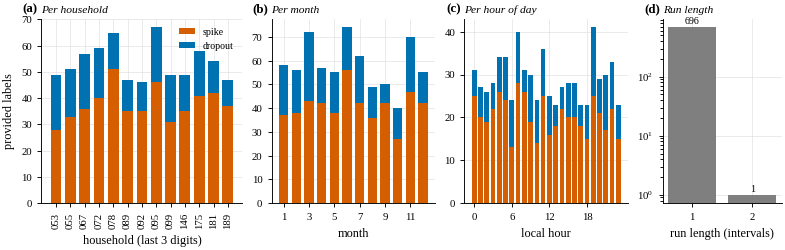

In [8]:
fig = P.fig_provided_labels(fx, labels, FIG); plt.show()

## C. Leakage in the provided derived columns (F3)

`power_2h_mean` equals a trailing mean that **includes** the current sample (median error 0), so it moves *at*
the anomaly and would leak the label; it would also not move when we inject. We drop all 64 derived columns and
recompute past-only features (section J).

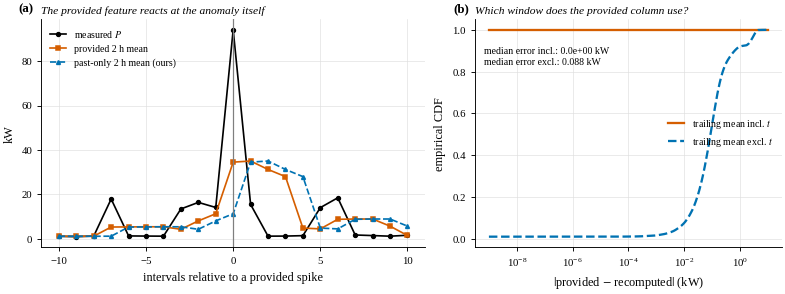

F3 - Rolling features include the current value (leakage)
   median |power_2h_mean - rolling incl. t|: 0.00e+00
   median |power_2h_mean - rolling excl. t|: 0.088
   pre-computed derived columns: 64


In [9]:
fig = P.fig_leakage(raw, FIG); plt.show()
metrics("F3")

## D. Load behaviour: schedule, calendar, temperature (F6, O1)

> **Correction to the first version.** F6 used to say the generator "does not model AC physics" because
> `corr(sub2_cooling, temperature) = 0`. The scatter in Fig. 10(d) shows why that conclusion was wrong: both
> thermal sub-meters grow **symmetrically with the distance from about 20 C** (a V-shape), which a linear
> correlation cannot see. Temperature *is* informative through `|T - 20 C|`; but "heating" and "cooling" are
> both high in winter **and** summer, so those labels are not physical.
>
> The weekly heat-map also shows a small **weekend uplift** rather than "no weekday effect".

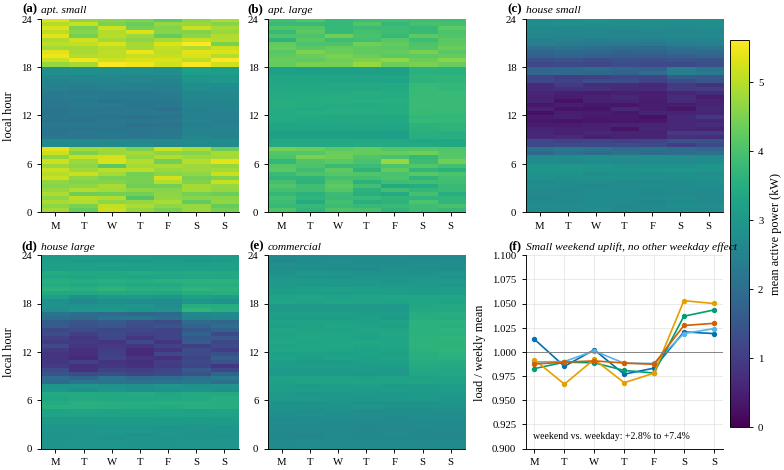

In [10]:
fig = P.fig_weekly_profile(fx, FIG); plt.show()

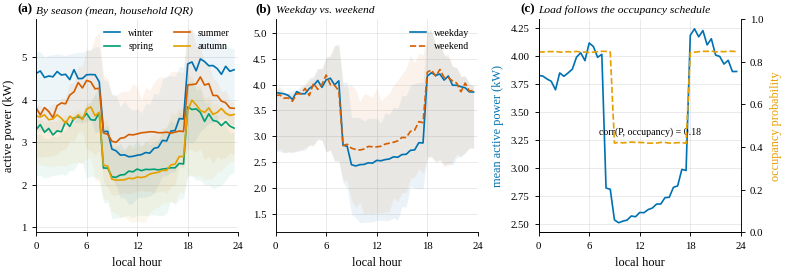

O1 - The daily profile is a two-level occupancy schedule
   occupancy probability, 18-09 h / 09-18 h: 0.85 / 0.42
   corr(P, occupancy_probability): 0.18
   weekend vs weekday load: +2.8% to +7.4%
   commercial_small day/night ratio: 1.13


In [11]:
fig = P.fig_daily_profiles(fx, FIG); plt.show()
metrics("O1")

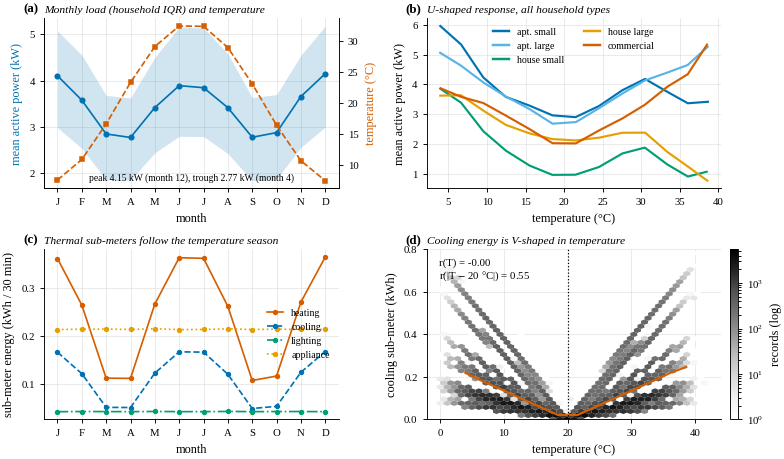

F6 - Thermal load is V-shaped in temperature (linear correlation is blind to it)
   corr(sub2_cooling, temperature): -0.000
   corr(sub2_cooling, |T - 20 C|): 0.549
   corr(sub1_heating, |T - 20 C|): 0.642
   monthly load: peak / trough: 4.16 kW / 2.77 kW
   mean load 00-07 h: 3.90 kW
   mean load 07-19 h: 2.93 kW


In [12]:
fig = P.fig_monthly_load_temperature(fx, FIG); plt.show()
metrics("F6")

## E. Heterogeneity and distributed resources (O2)

PV follows cloud cover and is zero at night, EV charging is confined to 18:00-08:00 and dominates the
household's power, and the battery charges at midday and discharges in the evening. Consequences for the
detectors: a single global threshold is wrong (EV households are bimodal) and a PV household legitimately
drops far below its peers at midday.

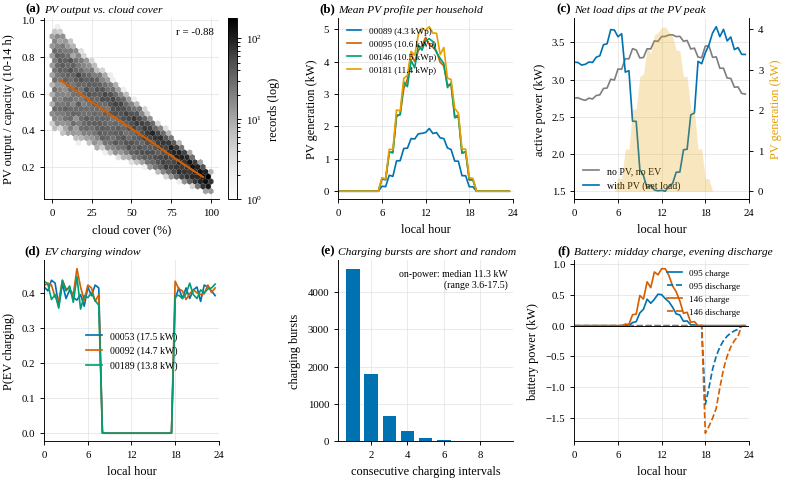

O2 - DER channels have clean, learnable signatures
   corr(PV / capacity, cloud cover), 10-14 h: -0.88
   PV output at night: 0.0 kW (max)
   EV charging probability, 18-08 h / 08-18 h: 0.40 / 0.0001
   EV on-power median (range): 11.3 kW (3.6-17.5)


In [13]:
fig = P.fig_der_profiles(fx, FIG); plt.show()
metrics("O2")

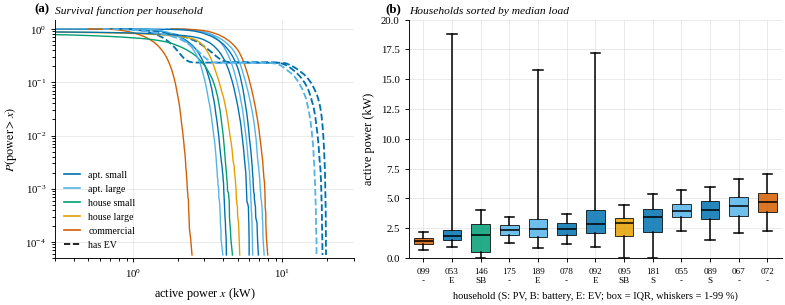

In [14]:
fig = P.fig_power_distribution(fx, FIG); plt.show()

## F. Weather (F5)

Temperature differs between households at the same instant and the weather *condition* is independent of
temperature and season (80 % of `snow` rows are above 10 C). Weather labels are therefore weak evidence; coherent
events must be injected rather than inferred from the weather columns.

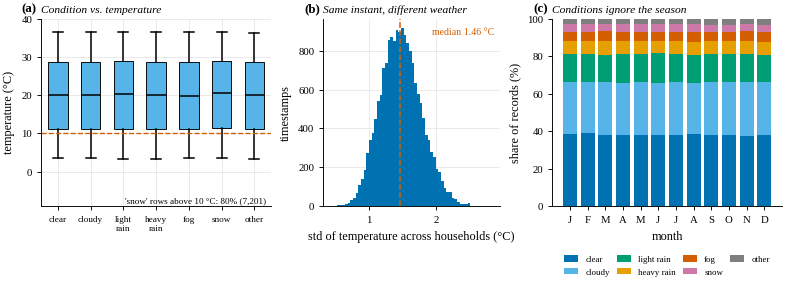

F5 - Weather is generated per row, not shared
   median between-household temp std: 1.46 C
   'snow' rows with temp > 10 C: 7201


In [15]:
fig = P.fig_weather(fx, FIG); plt.show()
metrics("F5")

## G. Energy balance and metadata (F7, F8)

Sub-meters are not a closed balance (an unmetered remainder dominates). The `sub-meters > total` rows occur
**only in PV households**, where net metering makes the total smaller than the gross sub-meter sum - so that
check is a PV artefact, not a fault indicator. Metadata contradicts itself, so size/type are not used as
features or explanations.

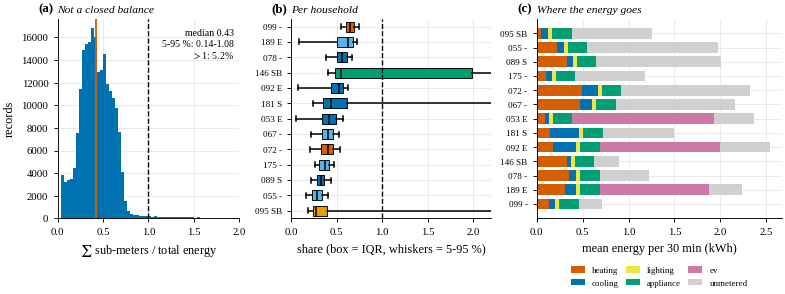

F7 - Sub-meters are not a closed energy balance
   median sub-meter share: 0.428
   5th percentile: 0.141
   95th percentile: 1.077
   sub-meter > total rows in PV households: 100.0%


In [16]:
fig = P.fig_submeter_balance(fx, FIG); plt.show()
metrics("F7")

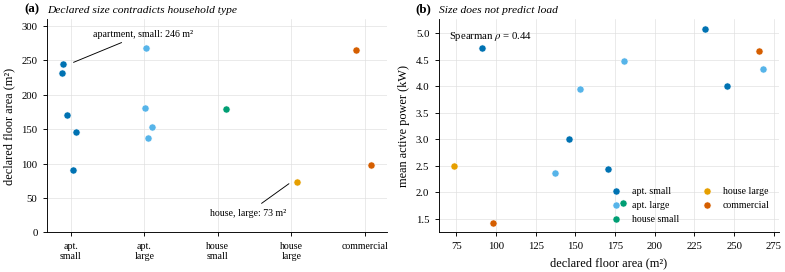

F8 - Metadata contradicts itself
   min size of house_large: 73 m2
   max size of apartment_small: 246 m2
   distinct household types: 5


In [17]:
fig = P.fig_metadata(fx, FIG); plt.show()
metrics("F8")

## H. Flat runs and cross-household coherence (F9, F10)

Natural flat runs reach 16 intervals but only at near-zero load, so stuck-at faults at normal load are
detectable by flatness. Households are weakly correlated at 30 minutes and strongly at one day; the 30-minute
matrix shows two clusters, which is what a coherence feature can exploit to separate a genuine network event from a
single-meter fault.

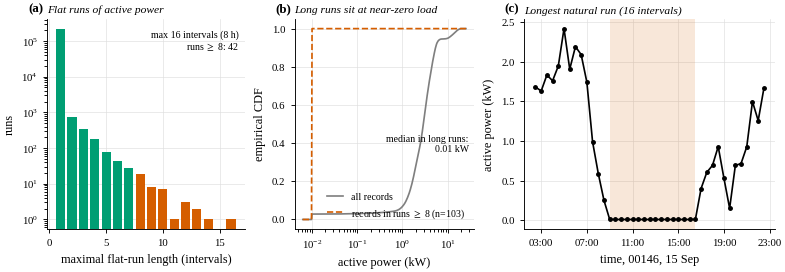

F9 - Natural flat runs reach ~16 intervals
   max flat run (baseline): 16
   rows in runs >= 8: 103 (0.0452%)
   load level of the long runs: ~0.01 kW


In [18]:
fig = P.fig_flat_runs(fx, FIG); plt.show()
metrics("F9")

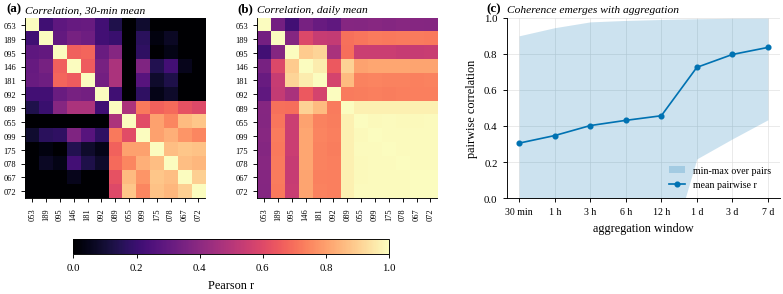

F10 - Households correlate daily but weakly at 30 min
   mean pairwise corr (30 min): 0.306
   mean pairwise corr (daily): 0.730


In [19]:
fig = P.fig_cross_household(fx, FIG); plt.show()
metrics("F10")

## I. Temporal splits and distribution shift 

Seasonality moves the level between splits (validation is the trough, test is rising). Any threshold or baseline
fitted on January-August will be biased out of sample, so thresholds are fixed on validation only and the Step 6
baseline needs a seasonal term (`|T - 20 C|` or a trailing level).

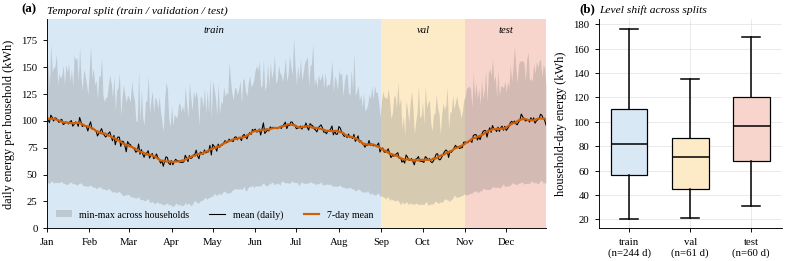

O3 - A baseline fitted on the training months drifts in validation and test
   median daily energy, train / val / test: 82 kWh / 71 kWh / 97 kWh
   median residual z, train / val / test: +0.00 / -0.99 / +0.45


In [20]:
fig = P.fig_temporal_splits(fx, splits, FIG); plt.show()
metrics("O3")

## J. Feature engineering prototype (blueprint section 6, input to Step 6)

All features are **past-only** (`shift(1)` before rolling) except those that deliberately use the current value;
everything fitted (hour-of-week median/MAD) is fitted on the **training window only**. `features.py` stays the
production implementation; this prototype is what the EDA needs to see the data the way the detectors will.

In [21]:
pd.DataFrame(eda_features.FEATURE_TABLE, columns=["feature", "definition", "type"]).style.hide(axis="index")

feature,definition,type
"p_roll_mean_{2h,24h,7d}",past-only rolling mean of active power,past-only
"p_roll_std_{2h,24h,7d}",past-only rolling std of active power,past-only
base_load_24h,past-only 24 h rolling minimum of P (night base load),past-only
load_factor_24h,past-only 24 h mean / max of P,past-only
p_ramp,"P(t) - P(t-1) (ramp rate, kW per interval)",current value
p_resid,P minus the household's hour-of-week median (train-fitted),current value
p_resid_z,"p_resid / (1.4826 * MAD of the same hour-of-week, train-fitted)",current value
unmetered_kwh,E - sum(sub1..sub4) - 0.5 * EV (energy not seen by sub-meters),current value
sub{1..4}_share,sub-meter k energy / total energy (only where E >= 0.1 kWh),current value
pv_offset_ratio,PV / (P + PV): how much of the gross load PV covers,current value


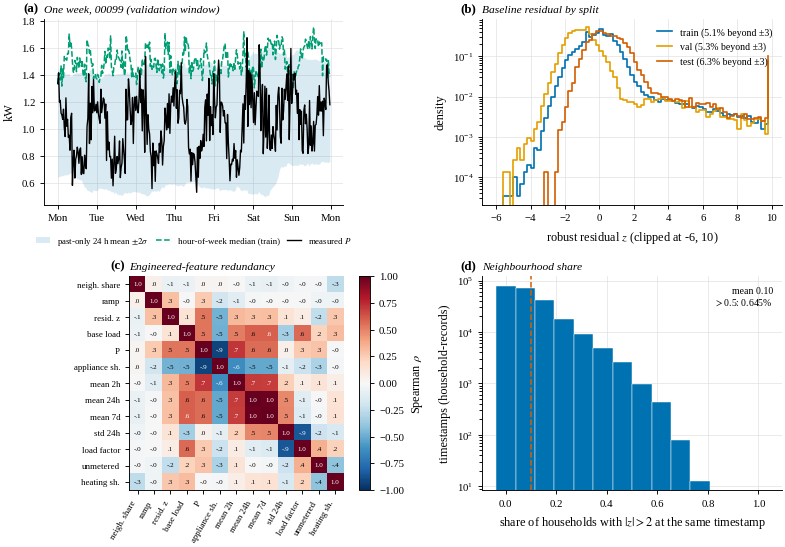

In [22]:
fig = P.fig_engineered_features(fx, splits, FIG); plt.show()

**Past-only test.** Perturb one *test-period* value and recompute: only the explicit current-value features may
change at that timestamp (the fitted baseline is unaffected because the point is outside the training window).

In [23]:
hh = "HH_00095_AUS"
cand = df.index[(df["household_id"] == hh) & (df["ts_utc"] >= pd.Timestamp("2020-11-10", tz="UTC"))]
t_idx = cand[100]
df2 = df.copy()
df2.loc[t_idx, "active_power_kw"] *= 5
fx2 = eda_features.engineer_features(df2, splits["train"][1])

feat = [c for c in fx.columns if c not in df.columns and pd.api.types.is_numeric_dtype(fx[c])]
key = (df.loc[t_idx, "household_id"], df.loc[t_idx, "ts_utc"])
a = fx.set_index(["household_id", "ts_utc"])[feat].loc[key].astype(float)
b = fx2.set_index(["household_id", "ts_utc"])[feat].loc[key].astype(float)
changed = sorted(c for c in feat if not np.isclose(a[c], b[c], equal_nan=True))
print("features that changed at t:", changed)
assert set(changed) <= set(eda_features.CURRENT_VALUE), "a past-only feature leaked the current value"
print("OK - every changed feature is a declared current-value feature")

features that changed at t: ['neigh_share', 'p_ramp', 'p_resid', 'p_resid_z']
OK - every changed feature is a declared current-value feature
